In [1]:
# 1. Data manipulation
import numpy as np
import pandas as pd

# 2. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Warning management
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from pathlib import Path

# Locate the dataset
dataset_path = Path("../dataset/raw/creditcard.csv")

# Load the dataset
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Total transactions:", df.shape[0])
print("Total columns:", df.shape[1])

Total transactions: 284807
Total columns: 31


In [4]:
# Count transactions in each class

class_counts = df["Class"].value_counts()

print(class_counts)

Class
0    284315
1       492
Name: count, dtype: int64


In [5]:
class_percentage = df["Class"].value_counts(normalize=True) * 100

print(class_percentage)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


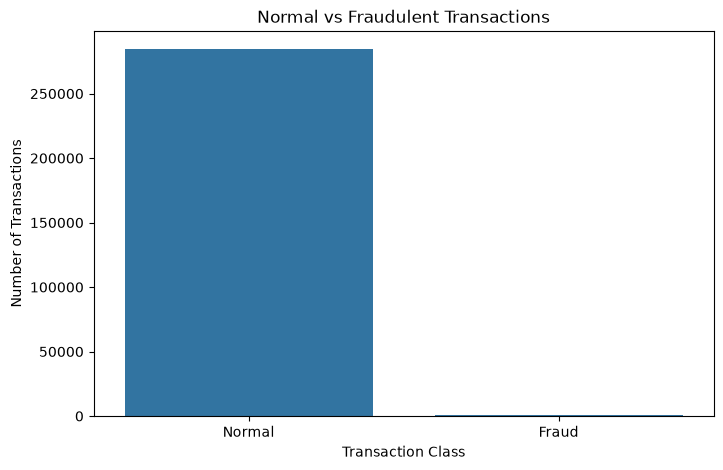

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()

In [7]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [8]:
df["Class"].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [9]:
print("Normal transactions:", (df["Class"] == 0).sum())

print("Fraud transactions:", (df["Class"] == 1).sum())

print("Total transactions:", len(df))

Normal transactions: 284315
Fraud transactions: 492
Total transactions: 284807


In [10]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [11]:
amount_by_class = df.groupby("Class")["Amount"].mean()

print(amount_by_class)

Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64


In [12]:
median_by_class = df.groupby("Class")["Amount"].median()

print(median_by_class)

Class
0    22.00
1     9.25
Name: Amount, dtype: float64


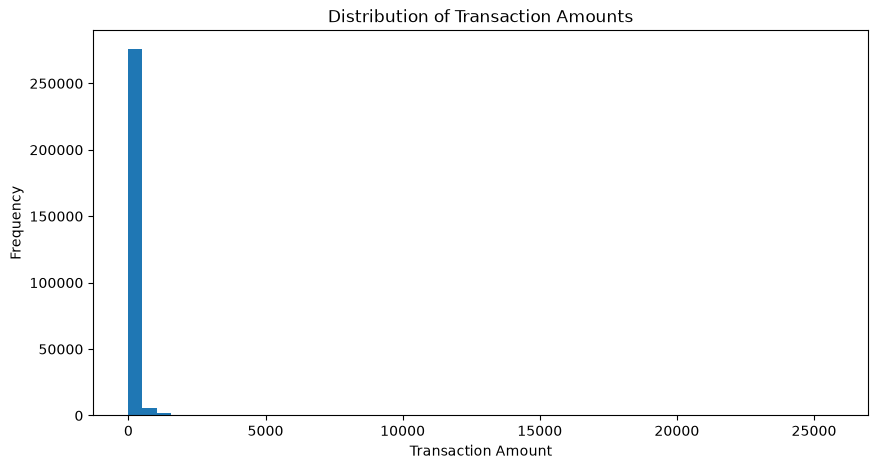

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(df["Amount"], bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

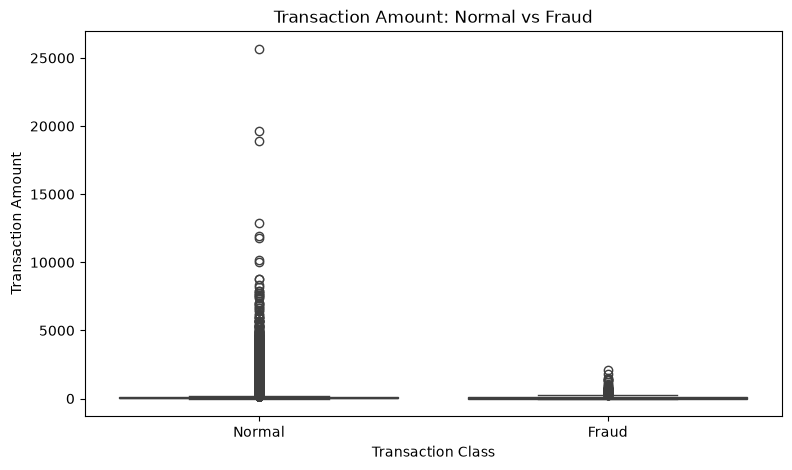

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.title("Transaction Amount: Normal vs Fraud")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")

plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()

In [15]:
amount_analysis = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

display(amount_analysis)

,count,mean,median,min,max,std
Class,,,,,,
0,284315,88.291022,22.00,0.0,25691.16,250.105092
1,492,122.211321,9.25,0.0,2125.87,256.683288


In [16]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

dataset_path = Path("../dataset/raw/creditcard.csv")

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (284807, 31)


In [17]:
print("Missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Total transactions:", len(df))

print("\nData types:")
print(df.dtypes.value_counts())

Missing values: 0
Duplicate rows: 1081
Total transactions: 284807

Data types:
float64    30
int64       1
Name: count, dtype: int64


In [18]:
class_counts = df["Class"].value_counts()

print("Normal transactions:", class_counts[0])
print("Fraud transactions:", class_counts[1])

print("\nPercentage distribution:")
print(df["Class"].value_counts(normalize=True) * 100)

Normal transactions: 284315
Fraud transactions: 492

Percentage distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


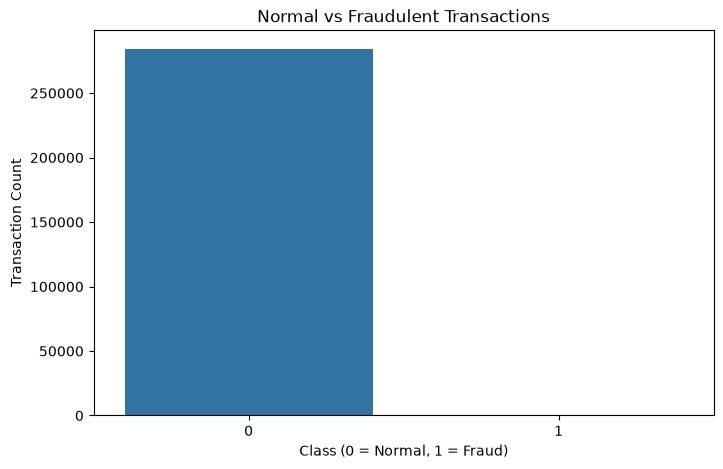

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Count")

plt.show()

In [20]:
display(
    df.groupby("Class")["Amount"].agg(
        ["count", "mean", "median", "min", "max"]
    )
)

,count,mean,median,min,max
Class,,,,,
0,284315,88.291022,22.00,0.0,25691.16
1,492,122.211321,9.25,0.0,2125.87


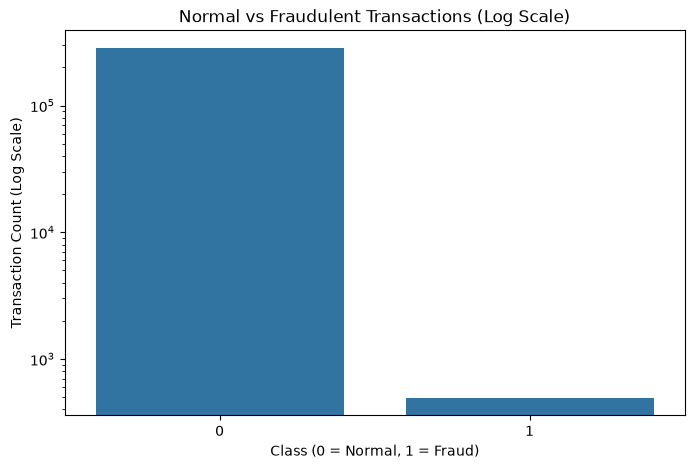

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.yscale("log")

plt.title("Normal vs Fraudulent Transactions (Log Scale)")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Count (Log Scale)")

plt.show()

In [22]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Total rows belonging to duplicate groups:",
      len(duplicate_rows))

print("\nDuplicate records by class:")

print(
    df[df.duplicated()]
    .groupby("Class")
    .size()
)

Total rows belonging to duplicate groups: 1854

Duplicate records by class:
Class
0    1062
1      19
dtype: int64


In [23]:
display(
    duplicate_rows.sort_values("Class").head(10)
)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
1382,1074.0,-2.248488,-0.195670,0.026949,-0.525780,-0.238759,-0.033359,0.162196,0.928520,-0.424215,...,-0.032208,-0.745757,-0.243193,-0.821633,-0.030402,0.335838,-0.286998,-0.243768,158.00,0
1383,1074.0,-2.445204,-0.505494,0.164511,-0.449658,0.460784,-0.509035,-0.490478,1.060597,-0.385591,...,0.060361,-0.802101,-0.299229,-0.831608,-0.055518,0.315454,-0.467257,-0.167591,1.00,0
1384,1074.0,-2.445204,-0.505494,0.164511,-0.449658,0.460784,-0.509035,-0.490478,1.060597,-0.385591,...,0.060361,-0.802101,-0.299229,-0.831608,-0.055518,0.315454,-0.467257,-0.167591,1.00,0
1683,1308.0,-1.322313,0.863591,1.844234,1.089375,0.771005,0.152191,1.491514,-0.917308,0.765538,...,-0.340315,0.315702,-0.133591,0.107112,0.246560,-0.309290,-0.510963,-0.349976,25.30,0
1684,1308.0,-1.322313,0.863591,1.844234,1.089375,0.771005,0.152191,1.491514,-0.917308,0.765538,...,-0.340315,0.315702,-0.133591,0.107112,0.246560,-0.309290,-0.510963,-0.349976,25.30,0
1685,1308.0,-1.379848,0.536720,2.647870,1.408111,0.126442,0.986525,0.960251,-0.629717,1.729173,...,-0.666874,-0.343574,0.022138,0.093532,0.011293,-0.503395,-0.438189,-0.346731,43.80,0
1686,1308.0,-1.379848,0.536720,2.647870,1.408111,0.126442,0.986525,0.960251,-0.629717,1.729173,...,-0.666874,-0.343574,0.022138,0.093532,0.011293,-0.503395,-0.438189,-0.346731,43.80,0
2003,1548.0,-1.559446,1.425546,0.812589,-1.129381,0.507528,0.183507,0.654304,0.088059,0.480018,...,-0.283995,-0.413642,-0.234995,-0.789509,0.324851,0.419737,0.329608,0.351346,5.00,0
2004,1548.0,-1.559446,1.425546,0.812589,-1.129381,0.507528,0.183507,0.654304,0.088059,0.480018,...,-0.283995,-0.413642,-0.234995,-0.789509,0.324851,0.419737,0.329608,0.351346,5.00,0


In [24]:
# Create a cleaned copy of our dataset

df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)

print("Cleaned dataset shape:", df_clean.shape)

print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset shape: (284807, 31)
Cleaned dataset shape: (283726, 31)
Duplicates remaining: 0


In [25]:
print("Transaction distribution after cleaning:")

print(df_clean["Class"].value_counts())

print("\nPercentage distribution:")

print(df_clean["Class"].value_counts(normalize=True) * 100)

Transaction distribution after cleaning:
Class
0    283253
1       473
Name: count, dtype: int64

Percentage distribution:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


In [26]:
from pathlib import Path

processed_path = Path("../dataset/processed")

processed_path.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    processed_path / "creditcard_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:
# Separate features and target

X = df_clean.drop("Class", axis=1)

y = df_clean["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (226980, 30)
Testing features: (56746, 30)
Training target: (226980,)
Testing target: (56746,)


In [29]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Make copies of training and testing data
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit on training data and transform
X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

# Transform testing data using training statistics
X_test_scaled[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Feature scaling completed!")

Feature scaling completed!


In [30]:
print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (226980, 30)
Testing data: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [31]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [32]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("Model created successfully!")

Model created successfully!


In [33]:
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [34]:
y_pred = logistic_model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("First 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!
First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [35]:
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("First 10 fraud probabilities:")
print(y_prob[:10])

First 10 fraud probabilities:
[0.02177687 0.02032174 0.01003082 0.01629384 0.21964489 0.06107924
 0.0221367  0.03856221 0.08735909 0.00183987]


In [36]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



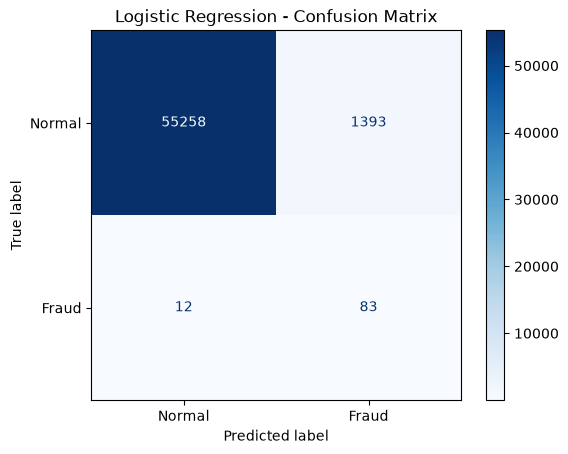

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [38]:
from sklearn.metrics import average_precision_score, roc_auc_score

pr_auc = average_precision_score(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

print("PR-AUC:", pr_auc)
print("ROC-AUC:", roc_auc)

PR-AUC: 0.6719353631354262
ROC-AUC: 0.9658392242808925


In [39]:
import joblib

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    logistic_model,
    "../models/logistic_regression.pkl"
)

print("Logistic Regression model saved!")

Logistic Regression model saved!


In [40]:
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree imported successfully!")

Decision Tree imported successfully!


In [41]:
decision_tree = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

print("Decision Tree created successfully!")

Decision Tree created successfully!


In [42]:
decision_tree.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [43]:
dt_pred = decision_tree.predict(X_test)

dt_prob = decision_tree.predict_proba(X_test)[:, 1]

print("Decision Tree predictions generated!")

Decision Tree predictions generated!


In [44]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

print(classification_report(y_test, dt_pred))

print("PR-AUC:",
      average_precision_score(y_test, dt_prob))

print("ROC-AUC:",
      roc_auc_score(y_test, dt_prob))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56651
           1       0.14      0.80      0.24        95

    accuracy                           0.99     56746
   macro avg       0.57      0.90      0.62     56746
weighted avg       1.00      0.99      0.99     56746

PR-AUC: 0.49606316640121273
ROC-AUC: 0.9073675477461725


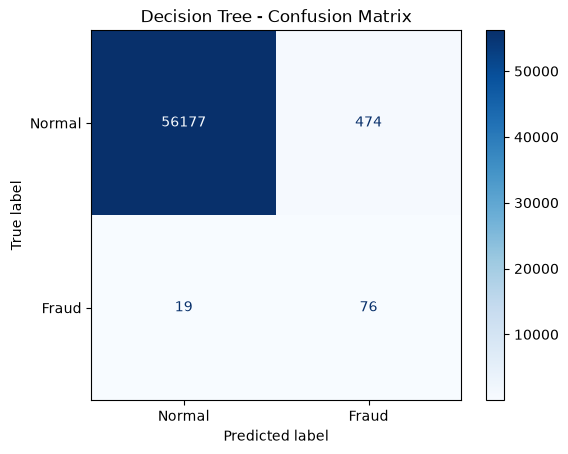

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=["Normal", "Fraud"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [46]:
joblib.dump(
    decision_tree,
    "../models/decision_tree.pkl"
)

print("Decision Tree saved successfully!")

Decision Tree saved successfully!


In [47]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [48]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created!")

Random Forest model created!


In [50]:
random_forest.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [51]:
rf_pred = random_forest.predict(X_test)

rf_prob = random_forest.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [52]:
print(classification_report(y_test, rf_pred))

print("PR-AUC:",
      average_precision_score(y_test, rf_prob))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_prob))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.90      0.75      0.82        95

    accuracy                           1.00     56746
   macro avg       0.95      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746

PR-AUC: 0.7991083642109457
ROC-AUC: 0.975165858548509


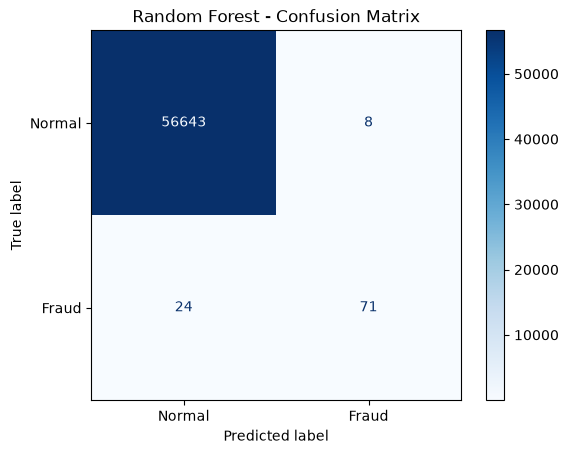

In [53]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Normal", "Fraud"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [54]:
joblib.dump(
    random_forest,
    "../models/random_forest.pkl"
)

print("Random Forest saved successfully!")

Random Forest saved successfully!


In [55]:
from imblearn.over_sampling import SMOTE

print("SMOTE imported successfully!")

SMOTE imported successfully!


In [56]:
print("Before SMOTE:")

print(y_train.value_counts())

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64


In [57]:
smote = SMOTE(
    sampling_strategy=0.1,
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("After SMOTE:")
print(y_train_smote.value_counts())

print("\nNew training shape:", X_train_smote.shape)

After SMOTE:
Class
0    226602
1     22660
Name: count, dtype: int64

New training shape: (249262, 30)


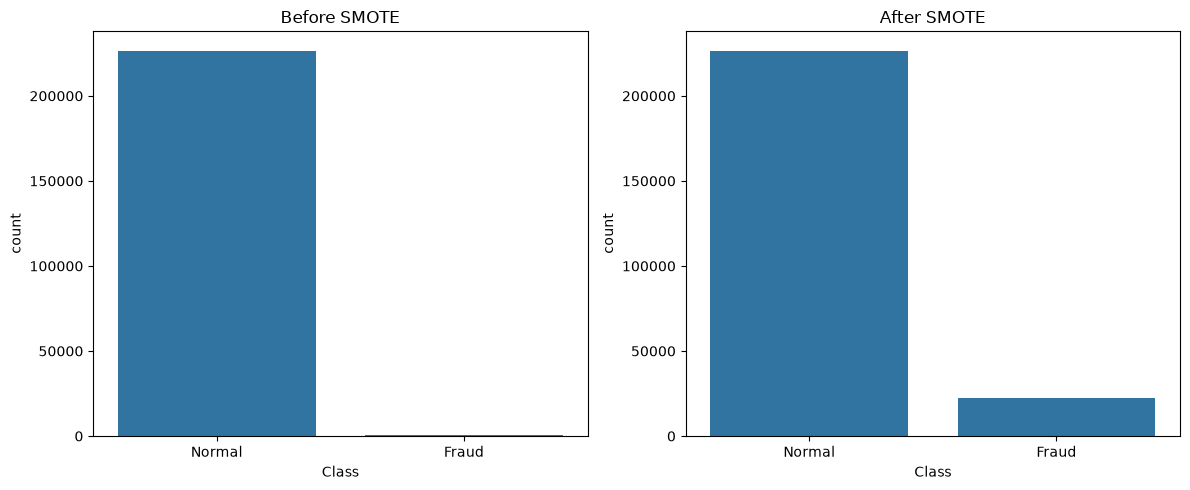

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")
axes[0].set_xticks([0, 1], ["Normal", "Fraud"])

sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title("After SMOTE")
axes[1].set_xticks([0, 1], ["Normal", "Fraud"])

plt.tight_layout()
plt.show()

In [59]:
rf_smote = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

print("SMOTE Random Forest training completed!")

SMOTE Random Forest training completed!


In [60]:
smote_pred = rf_smote.predict(X_test_scaled)

smote_prob = rf_smote.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, smote_pred))

print("PR-AUC:",
      average_precision_score(y_test, smote_prob))

print("ROC-AUC:",
      roc_auc_score(y_test, smote_prob))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.78      0.84        95

    accuracy                           1.00     56746
   macro avg       0.96      0.89      0.92     56746
weighted avg       1.00      1.00      1.00     56746

PR-AUC: 0.8178257764124974
ROC-AUC: 0.9752148194531802


In [61]:
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split

dataset_path = Path("../dataset/processed/creditcard_clean.csv")

df = pd.read_csv(dataset_path)

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (226980, 30)
Testing: (56746, 30)


In [62]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier

preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), ["Time", "Amount"])
    ],
    remainder="passthrough"
)

pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(
        sampling_strategy=0.1,
        random_state=42
    )),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [63]:
param_grid = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [8, 12, 16],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [2, 5, 10]
}

In [66]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

param_grid = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [8, 12],
    "model__min_samples_split": [5, 10],
    "model__min_samples_leaf": [5, 10]
}

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=4,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=2
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("Best CV PR-AUC:")
print(search.best_score_)

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Best parameters:
{'model__n_estimators': 50, 'model__min_samples_split': 10, 'model__min_samples_leaf': 10, 'model__max_depth': 12}
Best CV PR-AUC:
0.8338369642551904
